# 26.2 BERT Pretraining

BERT's central idea is **pretrain a general-purpose language representation model on unlabeled text**, then reuse those representations for downstream tasks.

The original BERT paper introduced two pretraining objectives:

1. **Masked Language Modeling (MLM)**
2. **Next Sentence Prediction (NSP)**

The important distinction for your syllabus: **MLM is fundamental to understanding BERT; NSP is mainly important as a historical/conceptual objective of the original BERT.** Later models such as RoBERTa changed the pretraining recipe and removed NSP. [arXiv](https://arxiv.org/abs/1810.04805?utm_source=chatgpt.com)



---

# 1. Why Does BERT Need Pretraining?

Imagine training a sentiment classifier directly:

```text
"I absolutely loved this movie"
             │
             ▼
         Classifier
             │
             ▼
           Positive
```

The problem is that the model needs to learn **language understanding and the task itself simultaneously**.

BERT changes the strategy:

```text
              Huge unlabeled corpus
                       │
                       ▼
                  PRETRAIN BERT
                       │
                   learns language
                       │
         ┌──────────────┼──────────────┐
         ▼              ▼              ▼
      Sentiment        NER            QA
      fine-tuning   fine-tuning   fine-tuning
```

This is the beginning of the modern **pretraining → fine-tuning** paradigm.

The original paper describes BERT as learning deep bidirectional representations from unlabeled text and subsequently fine-tuning those representations for downstream tasks. [arXiv](https://arxiv.org/abs/1810.04805?utm_source=chatgpt.com)

---

# 2. Masked Language Modeling — MLM

This is the **core BERT pretraining objective**.

The intuition is very simple:

> **Hide some tokens and force BERT to figure out what they were using the surrounding context.**

For example:

```text
Original:

The cat is sitting on the mat.

              ↓ mask

The cat is [MASK] on the mat.

              ↓ BERT

The cat is sitting on the mat.
```



---

# 3. Why MLM Makes BERT Bidirectional

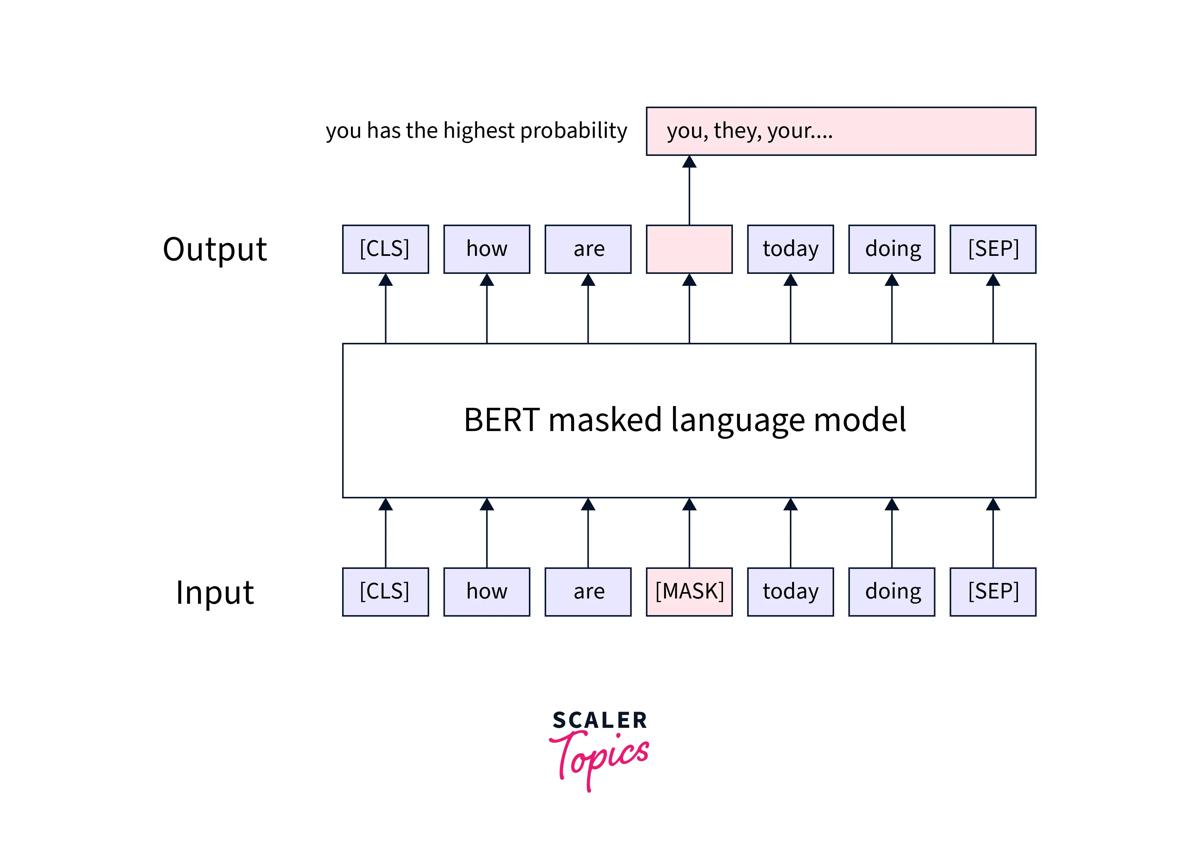

This is the key insight.

Suppose:

```text
The cat sat on the [MASK] because it was tired.
```

To predict `[MASK]`, BERT can use:

### Left context

```text
The cat sat on the
```

### Right context

```text
because it was tired
```

So:

$$
P(x_i \mid x_1,\ldots,x_{i-1},x_{i+1},\ldots,x_n)
$$

The model predicts the missing token using **both sides of the context**.

That's fundamentally different from a traditional left-to-right language model:

$$
P(x_i \mid x_1,\ldots,x_{i-1})
$$

So:

```text
Autoregressive LM:

The → cat → sat → on → the → ...


BERT MLM:

The ← cat ← sat ← [MASK] → because → it → ...
                ↑
           both directions
```

This is why the original BERT paper emphasizes **joint conditioning on left and right context**. [arXiv](https://arxiv.org/abs/1810.04805?utm_source=chatgpt.com)

---

# 4. What Exactly Gets Masked?

The original BERT training procedure selected **15% of input WordPiece tokens** as prediction candidates.

Importantly, **not all selected tokens were literally replaced by `[MASK]`**.

The original strategy was approximately:

| Selected token | What happens |
|---|---:|
| 80% | Replace with `[MASK]` |
| 10% | Replace with a random token |
| 10% | Leave unchanged |

So if:

```text
Original:

The dog is running quickly.
```

A possible training example could become:

```text
The dog is [MASK] quickly.
```

Another could theoretically contain a random replacement or unchanged selected token.

The prediction target remains the **original token**.

The original BERT procedure and these proportions are documented in later descriptions of the original BERT setup, including RoBERTa's detailed comparison. [arXiv](https://arxiv.org/pdf/1907.11692?utm_source=chatgpt.com)

### Why not mask 100%?

Because `[MASK]` appears during pretraining but generally isn't present in ordinary downstream inputs.

The unchanged/random cases reduce this mismatch between pretraining and later use.

---

# 5. MLM Architecture

Suppose:

```text
[CLS] The cat [MASK] on the mat [SEP]
```

The entire sequence enters the Transformer encoder.

```text
       Input tokens
            │
            ▼
[CLS] The cat [MASK] on the mat [SEP]
            │
            ▼
 ┌──────────────────────────────┐
 │     BERT Transformer         │
 │                              │
 │  Self-Attention              │
 │       ↓                      │
 │  Feed Forward                │
 │       ↓                      │
 │  ...                         │
 └──────────────────────────────┘
            │
            ▼
 Contextual representations
            │
            ▼
      representation at
         [MASK] position
            │
            ▼
        Linear layer
            │
            ▼
          Softmax
            │
            ▼
 Probability over vocabulary
```

The model produces a probability distribution:

$$
P(x_i=v \mid x_{\setminus i})
$$

for every possible vocabulary token \(v\) at the masked position.

---

# 6. MLM Loss

Suppose the true token is:

```text
The cat is [sleeping].
```

BERT might produce:

| Candidate | Probability |
|---|---:|
| sleeping | 0.72 |
| sitting | 0.12 |
| running | 0.05 |
| eating | 0.03 |
| ... | ... |

The training objective is essentially **cross-entropy over the masked positions**.

For masked positions \(M\):

$$
\boxed{
\mathcal{L}_{MLM}
=
-\sum_{i\in M}
\log P(x_i \mid x_{\setminus M})
}
$$

The model is rewarded when it assigns high probability to the original tokens.

### Important

BERT does **not** calculate the MLM loss equally over every token in the sequence.

The loss is focused on the **selected prediction positions**.

---

# 7. A Subtle but Important Point

BERT sees:

```text
The cat is [MASK] on the mat
```

during training.

But it is **not simply learning to replace `[MASK]` with a word using a dictionary**.

The Transformer is producing a contextual representation at that position:

$$
h_i = f(x_1,\ldots,x_n)
$$

Then:

$$
h_i \rightarrow \text{vocabulary classifier}
$$

So the model learns useful representations of:

- syntax
- semantic relationships
- word meaning
- contextual dependencies

This is why the pretraining objective can create representations useful for many downstream tasks.

---

# 8. Contextual Representations

This is probably the **most important conceptual outcome** of BERT pretraining.

Consider:

```text
I went to the bank to deposit money.

The river bank was beautiful.
```

The word:

```text
bank
```

has different meanings.

A traditional static embedding might give:

$$
E(\text{bank}) = \text{one vector}
$$

BERT instead produces:

$$
h_{\text{bank}}^{(sentence1)}
\neq
h_{\text{bank}}^{(sentence2)}
$$

because the representation depends on surrounding context.



Conceptually:

```text
                    BERT
                      │
           ┌───────────┴───────────┐
           │                       │
"I deposited money at the bank"   "river bank"
           │                       │
           ▼                       ▼
     contextual vector        contextual vector
        for bank                  for bank
           │                       │
           └─────── different ─────┘
                  meanings
```

This is a major evolution from **Word2Vec/GloVe-style static embeddings** that you studied earlier.

---

# 9. Original Next Sentence Prediction — NSP

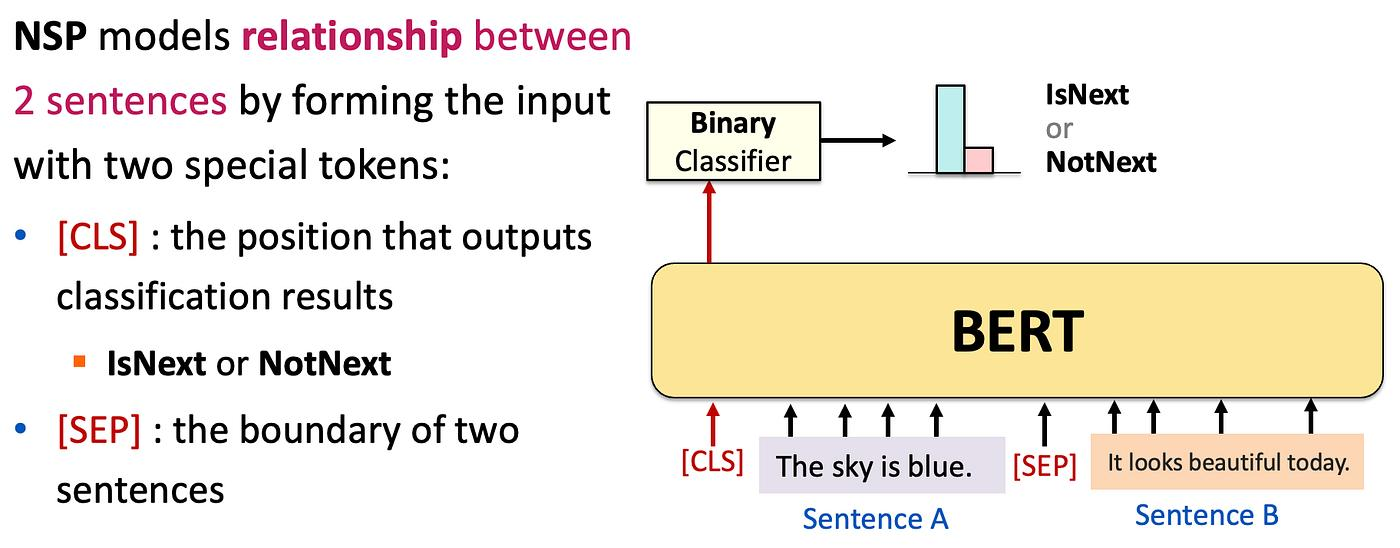

Now we come to the second original BERT objective.

The question was:

> **Does sentence B actually follow sentence A in the original text?**

Example:

### Positive

```text
Sentence A:
The weather was cold.

Sentence B:
I decided to wear a jacket.
```

These are a genuine consecutive pair.

Label:

```text
IsNext
```

### Negative

```text
Sentence A:
The weather was cold.

Sentence B:
The football team won the championship.
```

These are not consecutive sentences from the source text.

Label:

```text
NotNext
```



---

# 10. How NSP Works

The input looks like:

```text
[CLS] Sentence A [SEP] Sentence B [SEP]
```

After passing through BERT:

```text
                 BERT
                  │
          contextual representations
                  │
                  ▼
               h_[CLS]
                  │
                  ▼
            Binary classifier
               /          \
              ▼            ▼
           IsNext       NotNext
```

The `[CLS]` representation is used for the sentence-pair classification.

The original BERT objective combined MLM and NSP:

$$
\boxed{
\mathcal{L}_{BERT}
=
\mathcal{L}_{MLM}
+
\mathcal{L}_{NSP}
}
$$

A useful mental model is:

```text
MLM → learn relationships between tokens

NSP → learn relationships between text segments
```

The original BERT paper introduced both objectives. [arXiv](https://arxiv.org/abs/1810.04805?utm_source=chatgpt.com)

---

# 11. Why NSP Is "Conceptual Awareness" in Your Syllabus

This is an important distinction.

You **should know what NSP was and why BERT originally used it**, but don't build your modern NLP understanding around NSP.

Later research showed that BERT's original pretraining recipe could be improved by changing training choices, and **RoBERTa removed NSP** while training with an improved MLM-based setup and more data. [arXiv](https://arxiv.org/pdf/1907.11692?utm_source=chatgpt.com)

So your priority should be:

```text
MLM
████████████████████  MUST KNOW

Contextual representations
████████████████████  MUST KNOW

NSP
██████████░░░░░░░░░░  Conceptual / historical
```

That's exactly why your syllabus labels NSP as **conceptual awareness**.

---

# 12. BERT Pretraining — Complete Picture

Put everything together:

```text
                Large unlabeled text
                        │
                        ▼
                  WordPiece tokenizer
                        │
                        ▼
       [CLS] Sentence A [SEP] Sentence B [SEP]
                        │
                        ▼
             Randomly select tokens
                        │
                        ▼
                    MLM masking
                        │
                        ▼
              ┌──────────────────┐
              │  BERT Encoder    │
              │                  │
              │ Self-Attention   │
              │       ↓          │
              │ Feed Forward     │
              │       ↓          │
              │   ...            │
              └──────────────────┘
                    │         │
                    │         │
             token outputs   [CLS]
                    │         │
                    ▼         ▼
                  MLM       NSP
                 head       head
                    │         │
                    ▼         ▼
              masked-token  IsNext /
               prediction   NotNext
```

During pretraining, the model learns parameters that encode useful linguistic information.

Then:

```text
                 PRETRAINED BERT
                      │
        ┌──────────────┼──────────────┐
        ▼              ▼              ▼
   Classification     NER            QA
        │              │              │
     fine-tune       fine-tune      fine-tune
```

This **pretraining → task-specific fine-tuning** paradigm is the real legacy of BERT.

---

# 13. BERT vs Word2Vec — Important Connection

You have already studied Word2Vec, so make this connection:

| | Word2Vec | BERT |
|---|---|---|
| Representation | Static | Contextual |
| `"bank"` | Same vector | Context-dependent vector |
| Architecture | Shallow embedding model | Transformer encoder |
| Context | Limited training objective | Bidirectional self-attention |
| Pretraining | Word prediction | Masked token prediction |
| Output | Word embedding | Representation for every token |

### Mental progression

```text
Word2Vec / GloVe
       │
       ▼
Static word representations
       │
       ▼
ELMo / contextual approaches
       │
       ▼
BERT
       │
       ▼
Pretrained contextual Transformer
       │
       ▼
Modern pretrained NLP
```

---

# 14. Common Mistakes ⚠️

### Mistake 1: "BERT predicts the next word."

Not exactly.

BERT's original MLM objective predicts **masked tokens**, not simply the next token in a left-to-right sequence.

---

### Mistake 2: "BERT masks every token."

No.

Only a subset of tokens are selected for the MLM objective.

---

### Mistake 3: "`[MASK]` and `attention_mask` are the same."

No.

```text
[MASK]
→ input token used for MLM

attention_mask
→ tells the model which positions should be attended to
```

---

### Mistake 4: "NSP is what makes BERT bidirectional."

No.

**Bidirectional self-attention + MLM training** is the important mechanism.

NSP is a separate sentence-pair objective.

---

### Mistake 5: "BERT learns one embedding for every word."

No.

BERT generates **context-dependent representations**.

---

# Must Know 🔴

You should be able to explain these without notes:

- What pretraining means.
- Why BERT uses MLM.
- Why MLM enables bidirectional contextual learning.
- What `[MASK]` represents.
- How masked-token prediction works.
- MLM cross-entropy concept.
- What contextual representation means.
- Why `"bank"` can have different representations in different contexts.
- What the original NSP objective was.
- How `[CLS]` was used for NSP.
- Why NSP is mainly historical/conceptual today.
- Pretraining → fine-tuning.

# Good to Know 🟡

- Original 15% token-selection strategy.
- 80/10/10 masking strategy.
- MLM loss formulation.
- Combined MLM + NSP objective.
- Why later models such as RoBERTa changed the pretraining recipe.

# Optional / Advanced 🟢

- Dynamic vs static masking.
- NSP vs sentence-order objectives.
- Why RoBERTa removed NSP.
- Alternative pretraining objectives such as replaced-token detection.
- Limitations of vanilla MLM.

---

## 🧠 What You Should Remember

If you remember only **five things**, remember these:

1. **BERT is pretrained, not initially trained for one specific NLP task.**
2. **MLM hides selected tokens and trains BERT to recover them from context.**
3. **Because BERT can attend to both sides of a masked token, it learns bidirectional contextual representations.**
4. **NSP was the original BERT sentence-pair objective: IsNext vs NotNext.**
5. **The pretrained representations are later fine-tuned for tasks such as classification, NER, and QA.**

---